# synthbench quickstart

Evaluate a scorer end to end, and reproduce the headline figure from the packaged data.

The question this benchmark asks is not "is this molecule complex?" but "was it made?".
The labels come from provenance, never from a score.


In [1]:
import numpy as np
import synthbench as sb

ref = sb.load_reference_sets()
sb.provenance_table()[["set", "n", "made", "known", "route_length", "source"]]

,set,n,made,known,route_length,source
0,ZINC_purchasable,3580,1,"purchasable, therefore made",unknown,SYBA easy test set
1,Enamine_on_demand,1000,1,made,2 to 3 steps by construction,synformer sample of Enamine make-on-demand
2,ChEMBL_kinase,2968,1,made,unknown,built from ChEMBL kinase actives
3,THQ_library,10000,1,made,"one step, demonstrated experimentally",enumerated aza-Diels-Alder tetrahydroquinoline...
4,THQ_made_assayed,57,1,synthesized and assayed,"one step, experimental",the subset of the THQ library actually made
5,BRICS_recombined,4776,0,no evidence of existence,not applicable,BRICS recombination of ChEMBL JAK inhibitor fr...
6,GDB17_enumerated,3581,0,no evidence of existence,not applicable,"SYBA hard test set, drawn from GDB-17"


## 1. Evaluate a scorer

Any callable from SMILES to float. Here, a deliberately weak one: molecular size.


In [2]:
from rdkit import Chem

def size_score(smiles):
    m = Chem.MolFromSmiles(smiles)
    return None if m is None else float(m.GetNumHeavyAtoms())

res = sb.evaluate(size_score, name="HeavyAtoms", direction="lower_easier")
print(res.summary())

synthbench: HeavyAtoms  (lower_easier, 25962 of 25962 scored)

  makeability AUC            0.307  (95% CI 0.303 to 0.312)
  without the easy negative  0.486  (dependence -0.178)
  hard case, THQ vs BRICS    0.188
  confirmed subset, n=57     0.283
  set-dependence spread      0.356

  nearest-neighbour baseline 0.785   (you are -0.477 against it)

  Below chance: on this material the score ranks never-made molecules
  above made ones. Check the direction argument before reading further.
  Inverted on the hard case: molecules made in one step rank below molecules
  never made. Every score tested so far fails here, the baseline included.


Size carries almost no makeability signal. That is the point of having a floor to compare against.

## 2. Where it sits against the published panel


In [3]:
cmp = res.compare_to_published()
cmp[["scorer", "makeability_auc", "ci_low", "ci_high",
     "auc_without_easy_negative", "hard_case_auc", "confirmed_subset_auc"]].round(3)

,scorer,makeability_auc,ci_low,ci_high,auc_without_easy_negative,hard_case_auc,confirmed_subset_auc
0,catalogue_sim,0.785,0.780,0.789,0.611,0.295,0.226
1,brsascore,0.706,0.702,0.710,0.418,0.001,0.011
2,sascore,0.691,0.687,0.696,0.401,0.017,0.044
3,rascore,0.647,0.643,0.652,0.491,0.016,0.026
4,scscore,0.352,0.346,0.359,0.464,0.266,0.162
5,HeavyAtoms,0.307,0.303,0.312,0.486,0.188,0.283


Read the `hard_case_auc` column. Every published score is near zero there: on the comparison
between molecules made in one step and molecules never made, they rank the made ones lower.

## 3. Which reference set decides the answer


In [4]:
res.leave_one_set_out().round(3)

,set_removed,makeability_auc
0,ZINC_purchasable,0.166
1,Enamine_on_demand,0.330
2,ChEMBL_kinase,0.355
3,THQ_library,0.379
4,BRICS_recombined,0.129
5,GDB17_enumerated,0.486


In [5]:
from synthbench import evaluate as _ev
import importlib
pub = importlib.import_module("synthbench.evaluate").published_table().set_index("scorer")
pub[["makeability_auc", "auc_without_easy_negative", "set_dependence_spread"]].round(3)

,makeability_auc,auc_without_easy_negative,set_dependence_spread
scorer,,,
sascore,0.691,0.401,0.580
scscore,0.352,0.464,0.238
rascore,0.647,0.491,0.318
brsascore,0.706,0.418,0.575
catalogue_sim,0.785,0.611,0.348


`set_dependence_spread` is how far a scorer's AUC moves as each set is removed in turn. For
SAscore it is 0.580, which is larger than the entire gap between the best and worst published
score. A reported AUC is a statement about the negative set as much as about the scorer.

## 4. Reproduce the headline figure


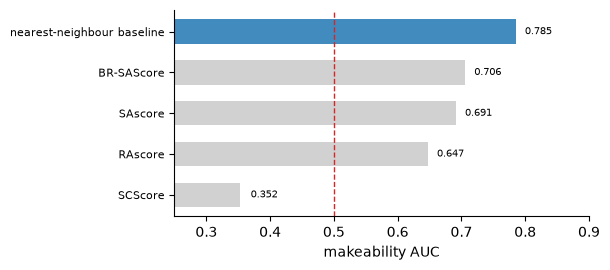

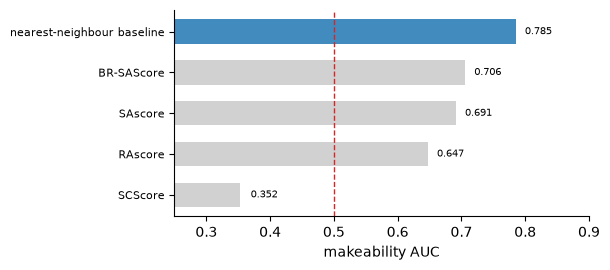

In [6]:
%matplotlib inline
import matplotlib as mpl
import matplotlib.pyplot as plt

f = pub
order = f.makeability_auc.sort_values().index.tolist()
LAB = {"sascore": "SAscore", "scscore": "SCScore", "rascore": "RAscore",
       "brsascore": "BR-SAScore", "catalogue_sim": "nearest-neighbour baseline"}
FOCAL = "catalogue_sim"

fig, ax = plt.subplots(figsize=(6.2, 2.8))
for i, c in enumerate(order):
    ax.barh(i, f.loc[c, "makeability_auc"], height=.6,
            color="#1f77b4" if c == FOCAL else "#999999",
            alpha=.85 if c == FOCAL else .45)
    ax.text(f.loc[c, "ci_high"] + .01, i, f"{f.loc[c, 'makeability_auc']:.3f}",
            va="center", fontsize=7)
ax.axvline(0.5, color="#d62728", lw=1.0, ls="--")
ax.set_yticks(range(len(order)))
ax.set_yticklabels([LAB[c] for c in order], fontsize=8)
ax.set_xlabel("makeability AUC")
ax.set_xlim(0.25, 0.90)
for s in ("top", "right"):
    ax.spines[s].set_visible(False)
fig.tight_layout()
fig

## 5. Scoring your own molecules with the published panel

Optional. The benchmark ships the panel precomputed, so this is only for molecules outside it.
No third-party weights are redistributed; `fetch_weights()` downloads them from the authors'
own repositories.


In [7]:
from synthbench import scorers
scorers.available()

{'sascore': 'ready',
 'scscore': 'ready',
 'rascore': "XGBoostError: [07:02:37] D:\\bld\\xgboost-split_1789510239727\\work\\src\\learner.cc:1007: Check failed: header[0] == '{' (C vs. {) : Invalid serialization file.",
 'brsascore': 'ready'}

## What this benchmark does not say

No set here is proven unmakeable. "Never made" means no evidence of existence. A true negative
set would need compounds that chemists attempted and failed to make, and no such collection is
public.

The nearest-neighbour baseline wins, but it fails the hard case too. It is a floor that exposes
how much of a published score is catalogue recognition, not a recommended scoring function.
